In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score
from sklearn.preprocessing import LabelEncoder

import statsmodels.api as sm

In [3]:
df = pd.read_csv("diabetes_prediction_dataset.csv")

print("Shape of dataset:", df.shape)

df.head()

Shape of dataset: (100000, 9)


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


In [4]:
print(df.columns)

Index(['gender', 'age', 'hypertension', 'heart_disease', 'smoking_history',
       'bmi', 'HbA1c_level', 'blood_glucose_level', 'diabetes'],
      dtype='object')


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB


In [6]:
print(df.isnull().sum())

gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64


In [7]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 3854


In [8]:
df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (96146, 9)


In [9]:
df.describe()

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,diabetes
count,96146.000000,96146.000000,96146.000000,96146.000000,96146.000000,96146.000000,96146.000000
mean,41.794326,0.077601,0.040803,27.321461,5.532609,138.218231,0.088220
std,22.462948,0.267544,0.197833,6.767716,1.073232,40.909771,0.283616
min,0.080000,0.000000,0.000000,10.010000,3.500000,80.000000,0.000000
25%,24.000000,0.000000,0.000000,23.400000,4.800000,100.000000,0.000000
50%,43.000000,0.000000,0.000000,27.320000,5.800000,140.000000,0.000000
75%,59.000000,0.000000,0.000000,29.860000,6.200000,159.000000,0.000000
max,80.000000,1.000000,1.000000,95.690000,9.000000,300.000000,1.000000


In [10]:
numeric_columns = df.select_dtypes(include=np.number).columns

for column in numeric_columns:
    print("\nColumn:", column)
    
    print("Frequency:")
    print(df[column].value_counts())
    
    print("Mean:", df[column].mean())
    print("Median:", df[column].median())
    print("Mode:", df[column].mode().tolist())
    print("Variance:", df[column].var())
    print("Standard Deviation:", df[column].std())
    print("Skewness:", df[column].skew())
    print("Kurtosis:", df[column].kurt())
    
    print("-----------------------------")


Column: age
Frequency:
age
80.00    4932
51.00    1566
47.00    1511
48.00    1508
53.00    1498
         ... 
0.48       83
1.00       83
0.40       66
0.16       59
0.08       36
Name: count, Length: 102, dtype: int64
Mean: 41.79432571297818
Median: 43.0
Mode: [80.0]
Variance: 504.58401386588974
Standard Deviation: 22.46294757741935
Skewness: -0.06244473606084344
Kurtosis: -1.0044156770165364
-----------------------------

Column: hypertension
Frequency:
hypertension
0    88685
1     7461
Name: count, dtype: int64
Mean: 0.07760073221974913
Median: 0.0
Mode: [0]
Variance: 0.07157960306733009
Standard Deviation: 0.2675436470322741
Skewness: 3.1576758354784182
Kurtosis: 7.971082493577766
-----------------------------

Column: heart_disease
Frequency:
heart_disease
0    92223
1     3923
Name: count, dtype: int64
Mean: 0.04080252948640609
Median: 0.0
Mode: [0]
Variance: 0.039138090143271395
Standard Deviation: 0.19783349095456865
Skewness: 4.642358789539726
Kurtosis: 19.55190184313021
--

In [11]:
X = df[['age', 'bmi', 'HbA1c_level', 'blood_glucose_level']]
y = df['diabetes']

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [13]:
linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

linear_predictions = linear_model.predict(X_test)

In [14]:
print("Linear Regression Coefficients:")

for feature, coef in zip(X.columns, linear_model.coef_):
    print(f"{feature}: {coef}")

print("Intercept:", linear_model.intercept_)

Linear Regression Coefficients:
age: 0.0019703574972963593
bmi: 0.004302320195719483
HbA1c_level: 0.08487865125516834
blood_glucose_level: 0.002362293431851159
Intercept: -0.9077948263029517


In [15]:
linear_r2 = r2_score(y_test, linear_predictions)

linear_rmse = np.sqrt(
    mean_squared_error(y_test, linear_predictions)
)

print("Linear Regression R2:", linear_r2)
print("Linear Regression RMSE:", linear_rmse)

Linear Regression R2: 0.3419391626837188
Linear Regression RMSE: 0.23156602735502113


In [16]:
logistic_model = LogisticRegression(max_iter=1000)

logistic_model.fit(X_train, y_train)

logistic_predictions = logistic_model.predict(X_test)

In [17]:
logistic_accuracy = accuracy_score(
    y_test,
    logistic_predictions
)

print("Logistic Regression Accuracy:", logistic_accuracy)

Logistic Regression Accuracy: 0.9577223088923557


In [18]:
print("Logistic Regression Coefficients:")

for feature, coef in zip(X.columns, logistic_model.coef_[0]):
    print(f"{feature}: {coef}")

Logistic Regression Coefficients:
age: 0.052754483913579335
bmi: 0.09100363338877174
HbA1c_level: 2.32829439057126
blood_glucose_level: 0.03318061779825884


In [19]:
X_multiple = df[
    ['age',
     'hypertension',
     'heart_disease',
     'bmi',
     'HbA1c_level',
     'blood_glucose_level']
]

y_multiple = df['diabetes']

X_multiple = sm.add_constant(X_multiple)

model = sm.OLS(y_multiple, X_multiple)

results = model.fit()

print(results.summary())

                            OLS Regression Results                            
Dep. Variable:               diabetes   R-squared:                       0.353
Model:                            OLS   Adj. R-squared:                  0.353
Method:                 Least Squares   F-statistic:                     8757.
Date:                Wed, 16 Sep 2026   Prob (F-statistic):               0.00
Time:                        15:44:04   Log-Likelihood:                 5691.6
No. Observations:               96146   AIC:                        -1.137e+04
Df Residuals:                   96139   BIC:                        -1.130e+04
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                  -0.8808    

In [20]:
corr = df.select_dtypes(include=np.number).corr()

print(corr)

                          age  hypertension  heart_disease       bmi  \
age                  1.000000      0.257305       0.238451  0.344797   
hypertension         0.257305      1.000000       0.119982  0.148111   
heart_disease        0.238451      0.119982       1.000000  0.061376   
bmi                  0.344797      0.148111       0.061376  1.000000   
HbA1c_level          0.106719      0.081441       0.068140  0.084423   
blood_glucose_level  0.114317      0.084834       0.070832  0.092543   
diabetes             0.264927      0.195710       0.170711  0.214932   

                     HbA1c_level  blood_glucose_level  diabetes  
age                     0.106719             0.114317  0.264927  
hypertension            0.081441             0.084834  0.195710  
heart_disease           0.068140             0.070832  0.170711  
bmi                     0.084423             0.092543  0.214932  
HbA1c_level             1.000000             0.171615  0.406408  
blood_glucose_level     0.1

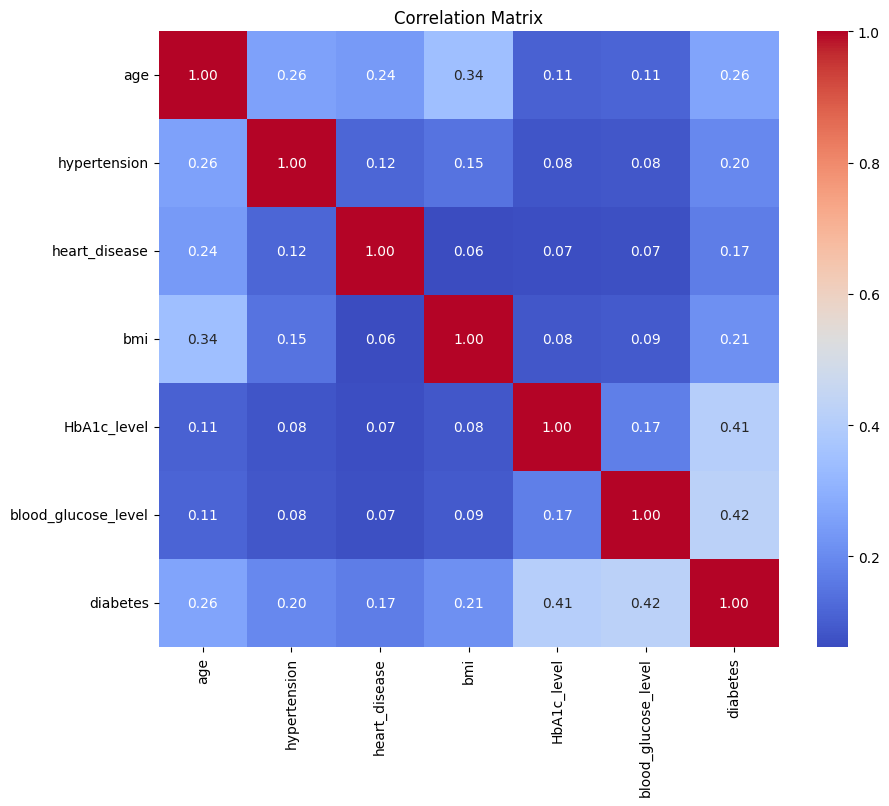

In [21]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Matrix")

plt.show()

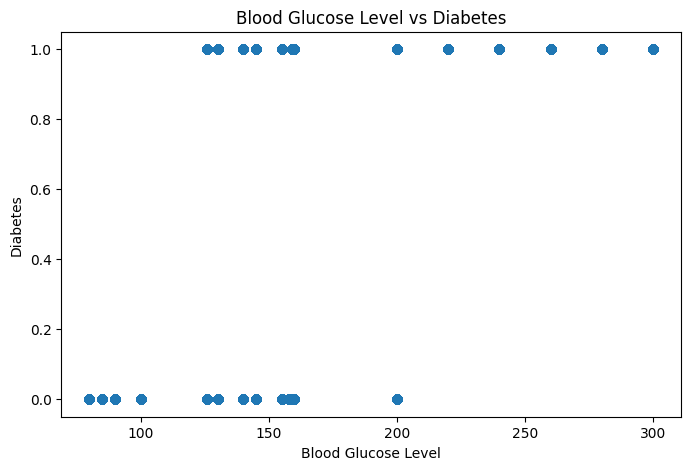

In [22]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df['blood_glucose_level'],
    df['diabetes'],
    alpha=0.3
)

plt.xlabel("Blood Glucose Level")
plt.ylabel("Diabetes")
plt.title("Blood Glucose Level vs Diabetes")

plt.show()

In [23]:
comparison = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Logistic Regression'
    ],
    'R2': [
        linear_r2,
        np.nan
    ],
    'RMSE': [
        linear_rmse,
        np.nan
    ],
    'Accuracy': [
        np.nan,
        logistic_accuracy
    ]
})

comparison

,Model,R2,RMSE,Accuracy
0,Linear Regression,0.341939,0.231566,NaN
1,Logistic Regression,NaN,NaN,0.957722
